# Ноутбуки для GitHub.
---
## Тема 3. Применение условных вероятностей в анализе данных
---

**Задание:** На некотором наборе данных продемонстрировать применение условных вероятностей. Рассматриваемый набор данных необходимо описать (назначение, описание признаков).

На реальных измерениях показать, как информация о признаке изменяет вероятность принадлежности объекта к определённому классу.
> Из набора Iris случайно и равновероятно выбирается одна строка. Найти вероятность того, что цветок относится к виду virginica: без дополнительной информации, при условии длины лепестка не менее 5 см и при противоположном условии. Сравнить прямой подсчёт с формулой Байеса, проверить формулу полной вероятности и рассмотреть зависимость событий.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

pd.options.display.float_format = '{:.6f}'.format
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

iris = load_iris()
df = pd.DataFrame(iris.data, columns=[
    'sepal_length', 'sepal_width', 'petal_length', 'petal_width'
])
df['species'] = iris.target_names[iris.target]
print('Число строк и столбцов:', df.shape)
print('Пропуски по столбцам:', df.isna().sum().to_dict())
print('Число наблюдений по видам:', df['species'].value_counts().to_dict())
df.head()

Число строк и столбцов: (150, 5)
Пропуски по столбцам: {'sepal_length': 0, 'sepal_width': 0, 'petal_length': 0, 'petal_width': 0, 'species': 0}
Число наблюдений по видам: {'setosa': 50, 'versicolor': 50, 'virginica': 50}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.100000,3.500000,1.400000,0.200000,setosa
1,4.900000,3.000000,1.400000,0.200000,setosa
2,4.700000,3.200000,1.300000,0.200000,setosa
3,4.600000,3.100000,1.500000,0.200000,setosa
4,5.000000,3.600000,1.400000,0.200000,setosa


### 2. События и таблица частот

Обозначим $A=\{\text{вид virginica}\}$ и $B=\{\text{длина лепестка}\geq5\text{ см}\}$.

$$\widehat P(A\mid B)=\frac{n(A\cap B)}{n(B)},\qquad n(B)>0.$$

Знаменатель — число строк, удовлетворяющих условию $B$, а не объём всего набора. Для равновероятного выбора строки эти частоты являются точными вероятностями на конечном наборе; как оценки вероятностей в популяции они требуют дополнительных предположений.

In [2]:
df['long_petal'] = df['petal_length'] >= 5.0
A = df['species'].eq('virginica')
B = df['long_petal']

counts = pd.crosstab(df['species'], df['long_petal']).reindex(columns=[False, True])
counts.columns = ['Лепесток < 5 см', 'Лепесток ≥ 5 см']
counts['Всего'] = counts.sum(axis=1)
counts.loc['Всего'] = counts.sum(axis=0)
counts

,Лепесток < 5 см,Лепесток ≥ 5 см,Всего
species,,,
setosa,50,0,50
versicolor,48,2,50
virginica,6,44,50
Всего,104,46,150


### 3. Безусловная, совместная и условные вероятности

Посчитаем число строк для каждого события и запишем явные числители и знаменатели.

In [3]:
N = len(df)
n_A = int(A.sum())
n_B = int(B.sum())
n_AB = int((A & B).sum())
n_notB = int((~B).sum())
n_A_notB = int((A & ~B).sum())

p_A = n_A / N
p_B = n_B / N
p_AB = n_AB / N
p_A_given_B = n_AB / n_B
p_B_given_A = n_AB / n_A
p_A_given_notB = n_A_notB / n_notB

result = pd.DataFrame([
    ['P(A)', n_A, N, p_A],
    ['P(B)', n_B, N, p_B],
    ['P(A ∩ B)', n_AB, N, p_AB],
    ['P(A | B)', n_AB, n_B, p_A_given_B],
    ['P(B | A)', n_AB, n_A, p_B_given_A],
    ['P(A | не B)', n_A_notB, n_notB, p_A_given_notB]
], columns=['Вероятность', 'Числитель', 'Знаменатель', 'Значение'])
result

,Вероятность,Числитель,Знаменатель,Значение
0,P(A),50,150,0.333333
1,P(B),46,150,0.306667
2,P(A ∩ B),44,150,0.293333
3,P(A | B),44,46,0.956522
4,P(B | A),44,50,0.880000
5,P(A | не B),6,104,0.057692


Получаем:

- $P(A)=50/150\approx0{,}3333$ — исходная вероятность вида virginica.
- $P(A\mid B)=44/46\approx0{,}9565$ — среди цветов с лепестком не менее 5 см вид virginica встречается в 95,65% случаев.
- $P(B\mid A)=44/50=0{,}88$ — у 88% цветов virginica лепесток имеет длину не менее 5 см.
- $P(A\mid\overline B)=6/104\approx0{,}0577$.

### 4. Условные вероятности для всех видов

Сначала нормируем таблицу по строкам: получаем $P(B\mid\text{вид})$. Затем по столбцам: получаем $P(\text{вид}\mid B)$ и $P(\text{вид}\mid\overline B)$. Сумма вероятностей в каждой соответствующей группе равна 1

In [4]:
by_species = pd.crosstab(df['species'], df['long_petal'], normalize='index')
by_species.columns = ['P(лепесток < 5 | вид)', 'P(лепесток ≥ 5 | вид)']
print('Условие — вид цветка; каждая строка суммируется в 1:')
display(by_species)

by_length = pd.crosstab(df['species'], df['long_petal'], normalize='columns')
by_length.columns = ['P(вид | лепесток < 5)', 'P(вид | лепесток ≥ 5)']
print('Условие — диапазон длины; каждый столбец суммируется в 1:')
display(by_length)

Условие — вид цветка; каждая строка суммируется в 1:


,P(лепесток < 5 | вид),P(лепесток ≥ 5 | вид)
species,,
setosa,1.000000,0.000000
versicolor,0.960000,0.040000
virginica,0.120000,0.880000


Условие — диапазон длины; каждый столбец суммируется в 1:


,P(вид | лепесток < 5),P(вид | лепесток ≥ 5)
species,,
setosa,0.480769,0.000000
versicolor,0.461538,0.043478
virginica,0.057692,0.956522


### 5. Проверка формулы Байеса

$$P(A\mid B)=\frac{P(B\mid A)P(A)}{P(B)}
=\frac{0{,}88\cdot(50/150)}{46/150}=\frac{44}{46}.$$


In [6]:
p_bayes = p_B_given_A * p_A / p_B
print(f'По формуле Байеса: {p_bayes:.6f}')
print(f'Прямым подсчётом: {p_A_given_B:.6f}')

По формуле Байеса: 0.956522
Прямым подсчётом: 0.956522


### 6. Формула полной вероятности и зависимость событий

Так как $B$ и $\overline B$ образуют полную группу событий,

$$P(A)=P(A\mid B)P(B)+P(A\mid\overline B)P(\overline B).$$

Независимость на рассматриваемом конечном наборе означала бы $P(A\cap B)=P(A)P(B)$. Сравним эти величины

In [8]:
p_total = p_A_given_B * p_B + p_A_given_notB * (1 - p_B)
print(f'По формуле полной вероятности: {p_total:.6f}')
print(f'Прямое значение P(A): {p_A:.6f}')
print(f'P(A ∩ B) = {p_AB:.6f}')
print(f'P(A)P(B) = {p_A * p_B:.6f}')


По формуле полной вероятности: 0.333333
Прямое значение P(A): 0.333333
P(A ∩ B) = 0.293333
P(A)P(B) = 0.102222


### 7. Визуальное сравнение


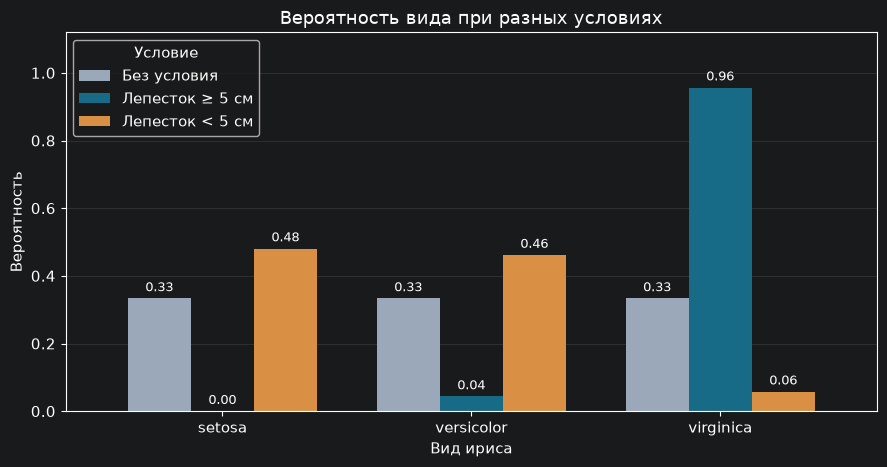

In [9]:
species = list(iris.target_names)
comparison = pd.DataFrame({
    'Без условия': df['species'].value_counts(normalize=True).reindex(species),
    'Лепесток ≥ 5 см': df.loc[B, 'species'].value_counts(normalize=True).reindex(species, fill_value=0),
    'Лепесток < 5 см': df.loc[~B, 'species'].value_counts(normalize=True).reindex(species, fill_value=0)
})

fig, ax = plt.subplots(figsize=(9, 4.8))
comparison.plot.bar(ax=ax, color=['#9AA8BA', '#176B87', '#D99045'], width=0.76)
ax.set(title='Вероятность вида при разных условиях', xlabel='Вид ириса', ylabel='Вероятность')
ax.set_ylim(0, 1.12)
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3, fontsize=9)
ax.legend(title='Условие', loc='upper left')
fig.tight_layout()
plt.show()